In [4]:
import tensorflow as tf
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


In [5]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add the channel dimension required by CNNs
x_train = x_train[..., None]
x_test = x_test[..., None]

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


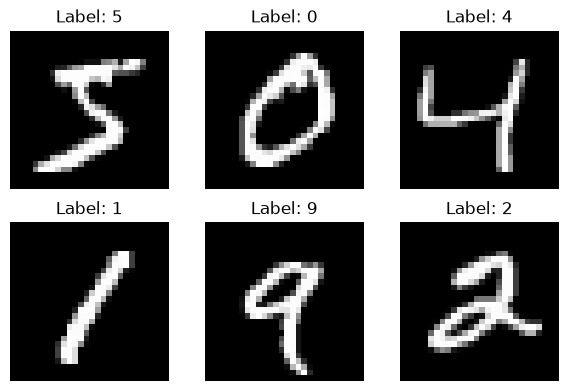

In [6]:
plt.figure(figsize=(6, 4))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [7]:
def create_cnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    return model

# Display the architecture
create_cnn().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
def train_model(optimizer, optimizer_name, epochs=10):
    model = create_cnn()

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    print(f"\nTraining with {optimizer_name}...")

    history = model.fit(
        x_train,
        y_train,
        epochs=epochs,
        batch_size=128,
        validation_split=0.1,
        verbose=1
    )

    test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

    print(f"{optimizer_name} - Test Loss: {test_loss:.4f}")
    print(f"{optimizer_name} - Test Accuracy: {test_accuracy:.4f}")

    return model, history, test_loss, test_accuracy

In [9]:
sgd_model, sgd_history, sgd_test_loss, sgd_test_accuracy = train_model(
    tf.keras.optimizers.SGD(learning_rate=0.01),
    "SGD"
)


Training with SGD...
Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.5529 - loss: 1.4737 - val_accuracy: 0.8968 - val_loss: 0.4099
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8887 - loss: 0.3818 - val_accuracy: 0.9373 - val_loss: 0.2348
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9198 - loss: 0.2708 - val_accuracy: 0.9500 - val_loss: 0.1812
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9355 - loss: 0.2158 - val_accuracy: 0.9590 - val_loss: 0.1500
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9471 - loss: 0.1790 - val_accuracy: 0.9673 - val_loss: 0.1290
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9551 - loss: 0.1532 - val_accuracy: 0.9707 - val_loss: 0.1144
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9607 - loss: 0.1346 - val_accuracy: 0.9735 - val_loss: 0.1044
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9648 - l

In [10]:
adam_model, adam_history, adam_test_loss, adam_test_accuracy = train_model(
    tf.keras.optimizers.Adam(learning_rate=0.001),
    "Adam"
)


Training with Adam...
Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9270 - loss: 0.2484 - val_accuracy: 0.9817 - val_loss: 0.0675
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9789 - loss: 0.0690 - val_accuracy: 0.9855 - val_loss: 0.0558
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9856 - loss: 0.0477 - val_accuracy: 0.9873 - val_loss: 0.0512
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9885 - loss: 0.0373 - val_accuracy: 0.9878 - val_loss: 0.0491
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9910 - loss: 0.0292 - val_accuracy: 0.9877 - val_loss: 0.0491
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9930 - loss: 0.0231 - val_accuracy: 0.9867 - val_loss: 0.0497
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9942 - loss: 0.0188 - val_accuracy: 0.9882 - val_loss: 0.0467
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9959 - 

In [11]:
rmsprop_model, rmsprop_history, rmsprop_test_loss, rmsprop_test_accuracy = train_model(
    tf.keras.optimizers.RMSprop(learning_rate=0.001),
    "RMSProp"
)


Training with RMSProp...
Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9290 - loss: 0.2316 - val_accuracy: 0.9697 - val_loss: 0.1068
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9803 - loss: 0.0639 - val_accuracy: 0.9793 - val_loss: 0.0693
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9876 - loss: 0.0418 - val_accuracy: 0.9837 - val_loss: 0.0591
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9909 - loss: 0.0305 - val_accuracy: 0.9850 - val_loss: 0.0522
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9932 - loss: 0.0229 - val_accuracy: 0.9867 - val_loss: 0.0518
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9952 - loss: 0.0173 - val_accuracy: 0.9858 - val_loss: 0.0561
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9968 - loss: 0.0127 - val_accuracy: 0.9863 - val_loss: 0.0587
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9975 - 

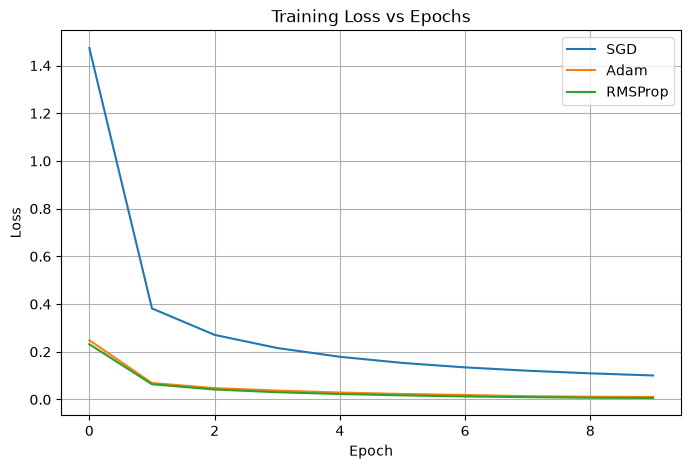

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(sgd_history.history["loss"], label="SGD")
plt.plot(adam_history.history["loss"], label="Adam")
plt.plot(rmsprop_history.history["loss"], label="RMSProp")

plt.title("Training Loss vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

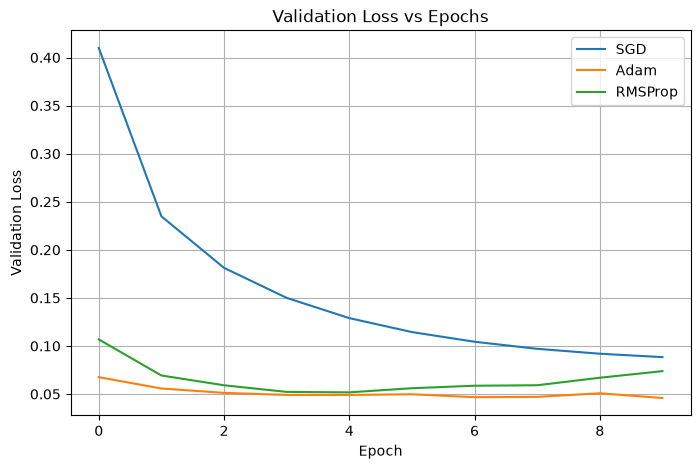

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(sgd_history.history["val_loss"], label="SGD")
plt.plot(adam_history.history["val_loss"], label="Adam")
plt.plot(rmsprop_history.history["val_loss"], label="RMSProp")

plt.title("Validation Loss vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
results = {
    "Optimizer": ["SGD", "Adam", "RMSProp"],
    "Test Loss": [sgd_test_loss, adam_test_loss, rmsprop_test_loss],
    "Test Accuracy": [sgd_test_accuracy, adam_test_accuracy, rmsprop_test_accuracy]
}

results_df = __import__("pandas").DataFrame(results)
results_df

,Optimizer,Test Loss,Test Accuracy
0,SGD,0.087341,0.9740
1,Adam,0.033814,0.9898
2,RMSProp,0.067577,0.9846
